Municipal Solid Waste Generation Prediction in India
This notebook trains a model using Population, Waste Collected, and Year as inputs, and predicts Waste Generated and Waste Treated

In [35]:
pip install pandas openpyxl scikit-learn sdv

In [36]:

import sys
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("All prediction-related imports completed successfully!")


All prediction-related imports completed successfully!


In [37]:
import pandas as pd
import numpy as np

# =====================================================
# STEP 1: LOAD DATASETS
# =====================================================

FILE_PATH = "/content/MSW Data for India.xlsx"
CSV_PATH = "/content/Waste_Management_India_20K-selected-columns.csv"

# Load Excel dataset
df1 = pd.read_excel(FILE_PATH, header=3)

# Load CSV dataset
df2 = pd.read_csv(CSV_PATH)

print("Dataset 1 original columns:")
print(df1.columns.tolist())

print("\nDataset 2 original columns:")
print(df2.columns.tolist())


# =====================================================
# STEP 2: CLEAN EXCEL DATASET
# =====================================================

df_raw = df1.copy()

# Remove extra spaces from column headers
df_raw.columns = df_raw.columns.astype(str).str.strip()

# Rename source columns
rename_map = {
    "Sr No": "Serial_No",
    "States and UT": "State_UT",
    "MSW Generation (MMTPA)": "MSW_Generation_MMTPA",
    "Total waste generation (tonnes/day)": "Waste_Generated_Tonnes_Per_Day",
    "Total waste Collection (tonnes/day)": "Waste_Collected_Tonnes_Per_Day",
    "Total waste Treatment (tonnes/day)": "Waste_Treated_Tonnes_Per_Day",
    "No. of compost plants": "Compost_Plants",
    "No. of existing dumpsites -": "Existing_Dumpsites",
    "No. of existing dumpsites - ": "Existing_Dumpsites",
    "Collection Rate %": "Source_Collection_Rate",
    "Treatment Rate %": "Source_Treatment_Rate"
}

df1 = df_raw.rename(columns=rename_map).copy()

# Check required columns
print("\nRenamed Excel columns:")
print(df1.columns.tolist())

# Remove rows without a valid serial number, if available
if "Serial_No" in df1.columns:
    df1["Serial_No"] = pd.to_numeric(
        df1["Serial_No"], errors="coerce"
    )
    df1 = df1[df1["Serial_No"].notna()].copy()

# Remove aggregate row
if "State_UT" in df1.columns:
    df1["State_UT"] = df1["State_UT"].astype(str).str.strip()

    df1 = df1[
        ~df1["State_UT"].str.lower().eq("total")
    ].copy()

# Remove unnecessary columns
df1 = df1.drop(
    columns=["Serial_No", "Unnamed: 0"],
    errors="ignore"
)

# Convert measurement columns to numeric
for col in df1.columns:
    if col != "State_UT":
        df1[col] = pd.to_numeric(df1[col], errors="coerce")

# Standardize known spelling variants
if "State_UT" in df1.columns:
    df1["State_UT"] = df1["State_UT"].replace({
        "Orrisa": "Odisha",
        "Dadra & Nagra Haveli and Daman & Diu":
            "Dadra & Nagar Haveli and Daman & Diu"
    })

# Remove duplicate state records
if "State_UT" in df1.columns:
    df1 = df1.drop_duplicates(
        subset=["State_UT"]
    ).reset_index(drop=True)

print("\nCleaned Excel dataset shape:", df1.shape)
display(df1.head())


# =====================================================
# STEP 3: CLEAN CSV DATASET
# =====================================================

# Remove spaces from CSV column headers
df2.columns = df2.columns.astype(str).str.strip()

# Standardize state column name
state_candidates = [
    col for col in df2.columns
    if col.strip().lower() in ["state", "state_ut", "states and ut"]
]

if "State" in df2.columns:
    state_col = "State"
elif state_candidates:
    state_col = state_candidates[0]
else:
    raise ValueError(
        "No state column found in the CSV dataset. "
        "Check df2.columns.tolist()."
    )

# Standardize state names
df2["State_UT"] = df2[state_col].astype(str).str.strip()

df2["State_UT"] = df2["State_UT"].replace({
    "Orrisa": "Odisha",
    "Dadra & Nagra Haveli and Daman & Diu":
        "Dadra & Nagar Haveli and Daman & Diu"
})

print("\nCleaned CSV dataset shape:", df2.shape)
display(df2.head())


# =====================================================
# STEP 4: CHECK MATCHING STATE NAMES
# =====================================================

excel_states = set(df1["State_UT"].dropna())
csv_states = set(df2["State_UT"].dropna())

matching_states = excel_states.intersection(csv_states)

print("\nNumber of states/UTs in Excel:", len(excel_states))
print("Number of states/UTs in CSV:", len(csv_states))
print("Matching state names:", len(matching_states))

print("\nMatching states:")
print(sorted(matching_states))

print("\nExcel states not found in CSV:")
print(sorted(excel_states - csv_states))


# =====================================================
# STEP 5: MERGE BOTH DATASETS
# =====================================================

# Keep all city records whose state matches the Excel data.
combined_df = pd.merge(
    df2,
    df1,
    on="State_UT",
    how="inner",
    suffixes=("_city", "_state")
)

print("\nCombined dataset shape:", combined_df.shape)
print("\nCombined dataset columns:")
print(combined_df.columns.tolist())

display(combined_df.head())


# =====================================================
# STEP 6: SAVE COMBINED DATASET
# =====================================================

combined_df.to_csv(
    "/content/Combined_MSW_Dataset.csv",
    index=False
)

print("\nCombined dataset saved successfully!")
print("File: /content/Combined_MSW_Dataset.csv")

Dataset 1 original columns:
['Unnamed: 0', 'Sr No', 'States and UT', 'MSW Generation (MMTPA)', 'Total waste generation (tonnes/day)', 'Total waste Collection (tonnes/day)', 'Total waste Treatment (tonnes/day)', 'No. of compost plants', 'No. of existing dumpsites - ', 'Collection Rate %', 'Treatment Rate %']

Dataset 2 original columns:
['Record_ID', 'City', 'State', 'Region', 'City_Category', 'Year', 'Month', 'Season', 'Population', 'Population_Density']

Renamed Excel columns:
['Unnamed: 0', 'Serial_No', 'State_UT', 'MSW_Generation_MMTPA', 'Waste_Generated_Tonnes_Per_Day', 'Waste_Collected_Tonnes_Per_Day', 'Waste_Treated_Tonnes_Per_Day', 'Compost_Plants', 'Existing_Dumpsites', 'Source_Collection_Rate', 'Source_Treatment_Rate']

Cleaned Excel dataset shape: (34, 9)


,State_UT,MSW_Generation_MMTPA,Waste_Generated_Tonnes_Per_Day,Waste_Collected_Tonnes_Per_Day,Waste_Treated_Tonnes_Per_Day,Compost_Plants,Existing_Dumpsites,Source_Collection_Rate,Source_Treatment_Rate
0,Andaman & Nicobar Islands,0.036500,115.0,70.0,5.0,1,1,0.608696,0.043478
1,Andhra Pradesh & Telangana,5.020575,13896.0,10656.0,9418.0,7,183,0.766839,0.883821
2,Arunachal Pradesh,0.066065,181.0,82.0,74.0,0,31,0.453039,0.902439
3,Assam,0.413910,1134.0,350.0,100.0,1,76,0.308642,0.285714
4,Bihar,0.828915,14820.0,NaN,NaN,0,156,NaN,NaN



Cleaned CSV dataset shape: (25203, 11)


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,State_UT
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,Tripura
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat



Number of states/UTs in Excel: 34
Number of states/UTs in CSV: 36
Matching state names: 30

Matching states:
['Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Excel states not found in CSV:
['Andaman & Nicobar Islands', 'Andhra Pradesh & Telangana', 'Dadra & Nagar Haveli and Daman & Diu', 'Jammu & Kashmir']

Combined dataset shape: (23057, 19)

Combined dataset columns:
['Record_ID', 'City', 'State', 'Region', 'City_Category', 'Year', 'Month', 'Season', 'Population', 'Population_Density', 'State_UT', 'MSW_Generation_MMTPA', 'Waste_Generated_Tonnes_Per_Day', 'Waste_Collected_Tonnes_Per_Day', 'Waste_Treated_Tonnes_Per_Day', 'Compost_Plants', 'Existing_Du

,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,State_UT,MSW_Generation_MMTPA,Waste_Generated_Tonnes_Per_Day,Waste_Collected_Tonnes_Per_Day,Waste_Treated_Tonnes_Per_Day,Compost_Plants,Existing_Dumpsites,Source_Collection_Rate,Source_Treatment_Rate
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,Tripura,0.153300,421.0,407.0,0.0,1,17,0.966746,0.000000
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh,6.132000,19180.0,15500.0,5197.0,7,609,0.808133,0.335290
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh,6.132000,19180.0,15500.0,5197.0,7,609,0.808133,0.335290
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat,3.702925,10145.0,9227.0,1354.0,15,170,0.909512,0.146743
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat,3.702925,10145.0,9227.0,1354.0,15,170,0.909512,0.146743



Combined dataset saved successfully!
File: /content/Combined_MSW_Dataset.csv


In [38]:
# Assign the merged combined_df to df to fix the NameError
df = combined_df

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())

# Data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (23057, 19)

Column Names:
['Record_ID', 'City', 'State', 'Region', 'City_Category', 'Year', 'Month', 'Season', 'Population', 'Population_Density', 'State_UT', 'MSW_Generation_MMTPA', 'Waste_Generated_Tonnes_Per_Day', 'Waste_Collected_Tonnes_Per_Day', 'Waste_Treated_Tonnes_Per_Day', 'Compost_Plants', 'Existing_Dumpsites', 'Source_Collection_Rate', 'Source_Treatment_Rate']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23057 entries, 0 to 23056
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Record_ID                       23057 non-null  object 
 1   City                            23057 non-null  object 
 2   State                           23057 non-null  object 
 3   Region                          23057 non-null  object 
 4   City_Category                   23057 non-null  object 
 5   Year                            23057 non-null 

,Year,Month,Population,Population_Density,MSW_Generation_MMTPA,Waste_Generated_Tonnes_Per_Day,Waste_Collected_Tonnes_Per_Day,Waste_Treated_Tonnes_Per_Day,Compost_Plants,Existing_Dumpsites,Source_Collection_Rate,Source_Treatment_Rate
count,23057.000000,23057.000000,2.305700e+04,23057.000000,22861.000000,22861.000000,22097.000000,22097.000000,23057.000000,23057.000000,22097.000000,22097.000000
mean,2020.503144,6.497029,1.837521e+06,7491.713840,3.230315,9986.307686,7146.471331,1730.863887,5.524526,208.424340,0.736602,0.228829
std,3.457748,3.452815,3.192265e+06,6245.581504,2.560778,8132.032932,5725.239312,1878.457388,5.574360,180.746275,0.180126,0.183105
min,2015.000000,1.000000,4.124500e+04,612.200000,0.032485,89.000000,49.000000,0.000000,0.000000,0.000000,0.308642,0.000000
25%,2017.000000,3.000000,3.391430e+05,3198.700000,0.992800,4100.000000,2350.000000,250.000000,1.000000,65.000000,0.555556,0.112899
50%,2021.000000,7.000000,8.938330e+05,5750.700000,2.372500,8675.000000,4298.000000,802.000000,4.000000,156.000000,0.808133,0.196637
75%,2024.000000,9.000000,1.948515e+06,10500.000000,5.601655,15272.000000,14234.000000,2000.000000,9.000000,327.000000,0.856504,0.315436
max,2026.000000,12.000000,2.083849e+07,35197.100000,8.238050,26820.000000,15500.000000,5197.000000,18.000000,609.000000,1.000000,1.000000



Data Types:
Record_ID                          object
City                               object
State                              object
Region                             object
City_Category                      object
Year                                int64
Month                               int64
Season                             object
Population                          int64
Population_Density                float64
State_UT                           object
MSW_Generation_MMTPA              float64
Waste_Generated_Tonnes_Per_Day    float64
Waste_Collected_Tonnes_Per_Day    float64
Waste_Treated_Tonnes_Per_Day      float64
Compost_Plants                      int64
Existing_Dumpsites                  int64
Source_Collection_Rate            float64
Source_Treatment_Rate             float64
dtype: object


In [39]:
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

# Handle missing numerical values using the median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna("Unknown")

# Display cleaned dataset
print("\nDataset Shape After Cleaning:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

display(df.head())


Missing Values in Each Column:
Record_ID                           0
City                                0
State                               0
Region                              0
City_Category                       0
Year                                0
Month                               0
Season                              0
Population                          0
Population_Density                  0
State_UT                            0
MSW_Generation_MMTPA              196
Waste_Generated_Tonnes_Per_Day    196
Waste_Collected_Tonnes_Per_Day    960
Waste_Treated_Tonnes_Per_Day      960
Compost_Plants                      0
Existing_Dumpsites                  0
Source_Collection_Rate            960
Source_Treatment_Rate             960
dtype: int64

Number of Duplicate Records: 0

Dataset Shape After Cleaning: (23057, 19)

Missing Values After Cleaning:
Record_ID                         0
City                              0
State                             0
Region             

,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,State_UT,MSW_Generation_MMTPA,Waste_Generated_Tonnes_Per_Day,Waste_Collected_Tonnes_Per_Day,Waste_Treated_Tonnes_Per_Day,Compost_Plants,Existing_Dumpsites,Source_Collection_Rate,Source_Treatment_Rate
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,Tripura,0.153300,421.0,407.0,0.0,1,17,0.966746,0.000000
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh,6.132000,19180.0,15500.0,5197.0,7,609,0.808133,0.335290
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,Uttar Pradesh,6.132000,19180.0,15500.0,5197.0,7,609,0.808133,0.335290
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat,3.702925,10145.0,9227.0,1354.0,15,170,0.909512,0.146743
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,Gujarat,3.702925,10145.0,9227.0,1354.0,15,170,0.909512,0.146743


In [40]:
# Identify important columns
target = "Waste_Generated_Tonnes_Per_Day"

# Check if the target exists
if target in df.columns:

    print("Mean Waste Generation:")
    print(df[target].mean())

    print("\nMedian Waste Generation:")
    print(df[target].median())

    print("\nStandard Deviation:")
    print(df[target].std())

    print("\nHighest Waste Generation:")
    print(df[target].max())

    print("\nLowest Waste Generation:")
    print(df[target].min())

else:
    print(
        f"Column '{target}' not found. "
        "Check the dataset's column names."
    )

Mean Waste Generation:
9975.160688727936

Median Waste Generation:
8675.0

Standard Deviation:
8098.288684753026

Highest Waste Generation:
26820.0

Lowest Waste Generation:
89.0


In [41]:
# Assign the merged combined_df to df to fix the NameError
df = combined_df

if (
    "State_UT" in df.columns
    and "Waste_Generated_Tonnes_Per_Day" in df.columns
):

    highest = df.loc[
        df["Waste_Generated_Tonnes_Per_Day"].idxmax()
    ]

    lowest = df.loc[
        df["Waste_Generated_Tonnes_Per_Day"].idxmin()
    ]

    print(
        "Highest waste generation:",
        highest["State_UT"],
        "-",
        highest["Waste_Generated_Tonnes_Per_Day"],
        "tonnes/day"
    )

    print(
        "Lowest waste generation:",
        lowest["State_UT"],
        "-",
        lowest["Waste_Generated_Tonnes_Per_Day"],
        "tonnes/day"
    )

Highest waste generation: Maharashtra - 26820.0 tonnes/day
Lowest waste generation: Sikkim - 89.0 tonnes/day


In [42]:
# Feature engineering

# 1. Collection rate
if (
    "Waste_Generated_Tonnes_Per_Day" in df.columns
    and "Waste_Collected_Tonnes_Per_Day" in df.columns
):

    df["Calculated_Collection_Rate"] = np.where(
        df["Waste_Generated_Tonnes_Per_Day"] > 0,
        (
            df["Waste_Collected_Tonnes_Per_Day"]
            / df["Waste_Generated_Tonnes_Per_Day"]
        ) * 100,
        np.nan
    )

# 2. Treatment rate
if (
    "Waste_Generated_Tonnes_Per_Day" in df.columns
    and "Waste_Treated_Tonnes_Per_Day" in df.columns
):

    df["Calculated_Treatment_Rate"] = np.where(
        df["Waste_Generated_Tonnes_Per_Day"] > 0,
        (
            df["Waste_Treated_Tonnes_Per_Day"]
            / df["Waste_Generated_Tonnes_Per_Day"]
        ) * 100,
        np.nan
    )

# 3. Uncollected waste
if (
    "Waste_Generated_Tonnes_Per_Day" in df.columns
    and "Waste_Collected_Tonnes_Per_Day" in df.columns
):

    df["Uncollected_Waste_Tonnes_Per_Day"] = (
        df["Waste_Generated_Tonnes_Per_Day"]
        - df["Waste_Collected_Tonnes_Per_Day"]
    )

# 4. Collected but not treated waste
if (
    "Waste_Collected_Tonnes_Per_Day" in df.columns
    and "Waste_Treated_Tonnes_Per_Day" in df.columns
):

    df["Collected_Not_Treated_Tonnes_Per_Day"] = (
        df["Waste_Collected_Tonnes_Per_Day"]
        - df["Waste_Treated_Tonnes_Per_Day"]
    )

print("Dataset after feature engineering:")
display(df.head())

Dataset after feature engineering:


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,...,Waste_Collected_Tonnes_Per_Day,Waste_Treated_Tonnes_Per_Day,Compost_Plants,Existing_Dumpsites,Source_Collection_Rate,Source_Treatment_Rate,Calculated_Collection_Rate,Calculated_Treatment_Rate,Uncollected_Waste_Tonnes_Per_Day,Collected_Not_Treated_Tonnes_Per_Day
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,...,407.0,0.0,1,17,0.966746,0.000000,96.674584,0.000000,14.0,407.0
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,15500.0,5197.0,7,609,0.808133,0.335290,80.813347,27.095933,3680.0,10303.0
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,15500.0,5197.0,7,609,0.808133,0.335290,80.813347,27.095933,3680.0,10303.0
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,9227.0,1354.0,15,170,0.909512,0.146743,90.951207,13.346476,918.0,7873.0
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,9227.0,1354.0,15,170,0.909512,0.146743,90.951207,13.346476,918.0,7873.0


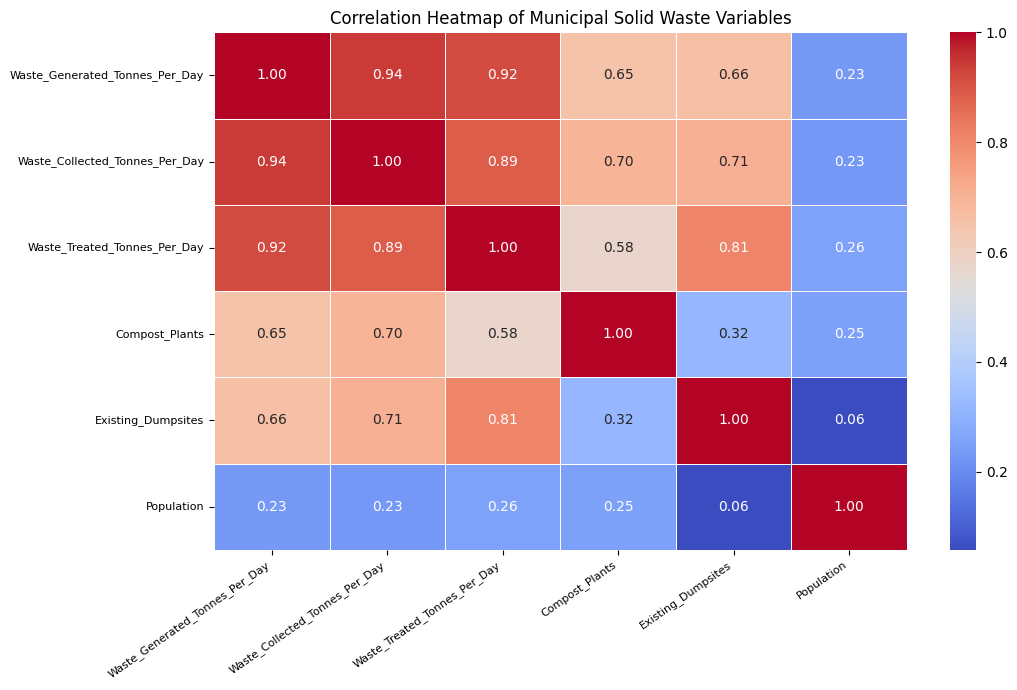

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Select relevant numerical variables
possible_columns = [
    "Waste_Generated_Tonnes_Per_Day",
    "Waste_Collected_Tonnes_Per_Day",
    "Waste_Treated_Tonnes_Per_Day",
    "Compost_Plants",
    "Existing_Dumpsites",
    "Population",
    "Population Density"
]

# Keep columns that exist in the dataset
available_columns = [
    col for col in possible_columns if col in df.columns
]

# Convert selected columns to numeric
heatmap_data = df[available_columns].copy()

for col in heatmap_data.columns:
    heatmap_data[col] = pd.to_numeric(
        heatmap_data[col], errors="coerce"
    )

# Remove columns with no usable values
heatmap_data = heatmap_data.dropna(axis=1, how="all")

# Calculate correlation matrix
correlation_matrix = heatmap_data.corr()

# Plot heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap of Municipal Solid Waste Variables",
    fontsize=12
)

# Make axis labels small and diagonal
plt.xticks(rotation=35, ha="right", fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

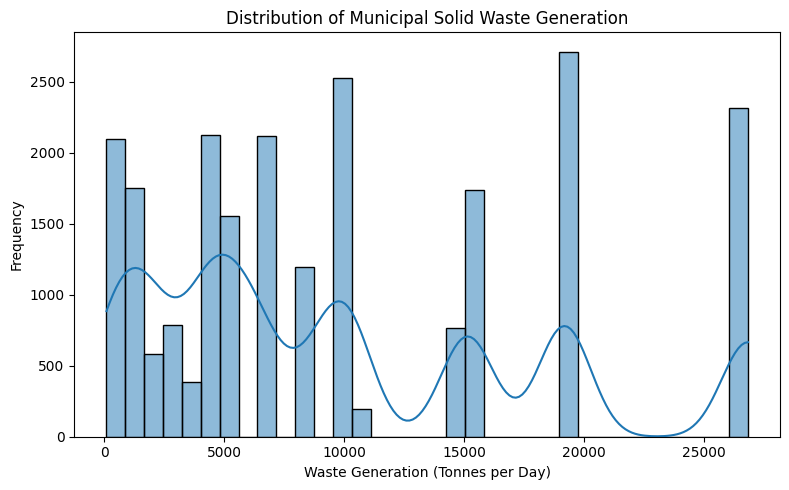

In [44]:
plt.figure(figsize=(8, 5))
sns.histplot(df[target], kde=True)
plt.title('Distribution of Municipal Solid Waste Generation')
plt.xlabel('Waste Generation (Tonnes per Day)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

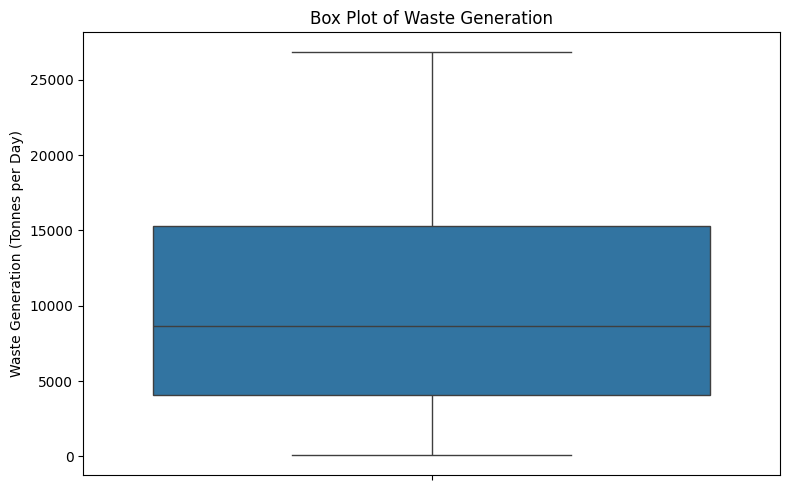

In [45]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df[target])
plt.title('Box Plot of Waste Generation')
plt.ylabel('Waste Generation (Tonnes per Day)')
plt.tight_layout()
plt.show()

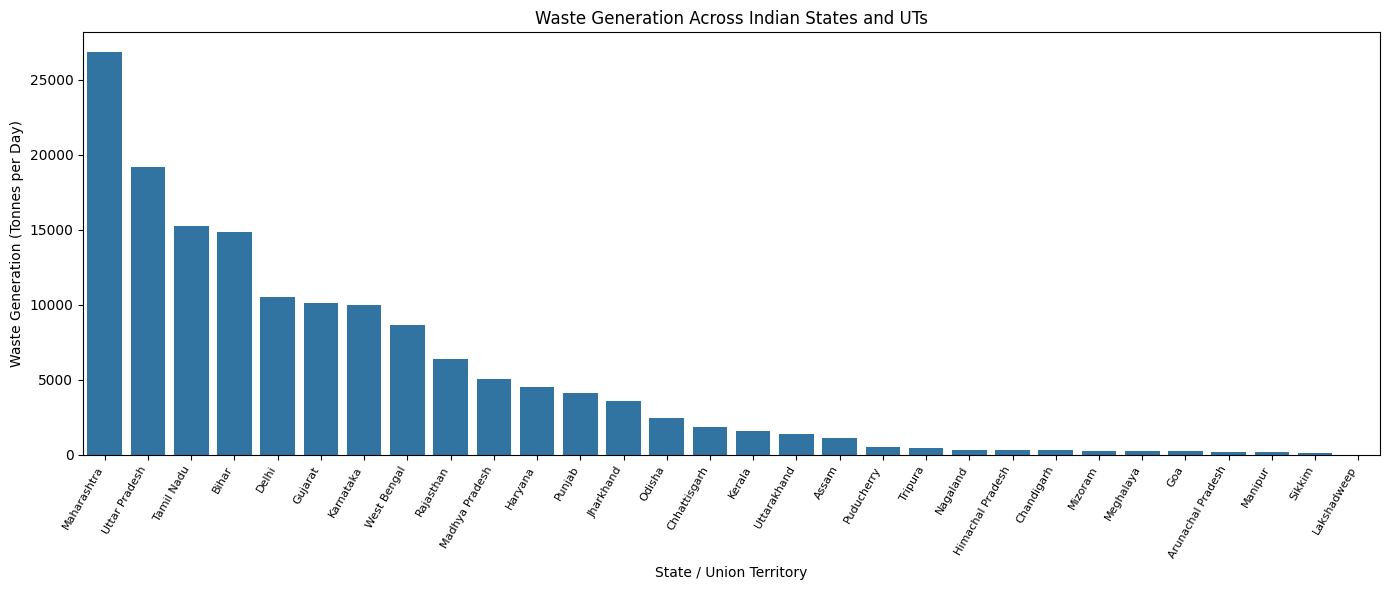

In [46]:
if 'State_UT' in df.columns:
    state_data = df.sort_values(target, ascending=False)

    plt.figure(figsize=(14, 6))
    sns.barplot(data=state_data, x='State_UT', y=target)

    plt.title('Waste Generation Across Indian States and UTs')
    plt.xlabel('State / Union Territory')
    plt.ylabel('Waste Generation (Tonnes per Day)')
    plt.xticks(rotation=60, ha='right', fontsize=8)
    plt.tight_layout()
    plt.show()

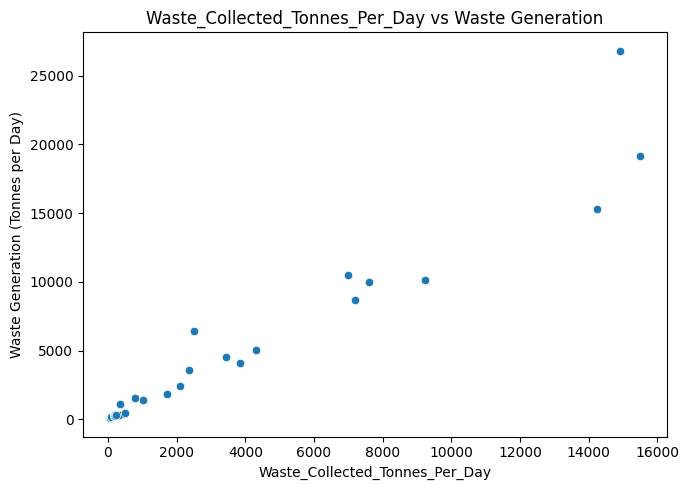

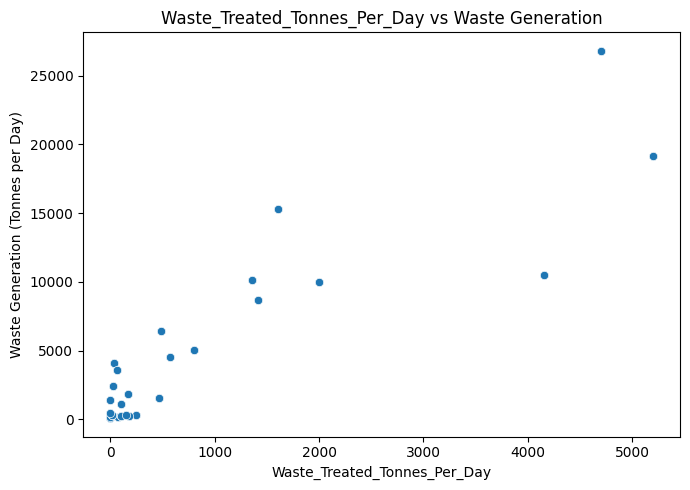

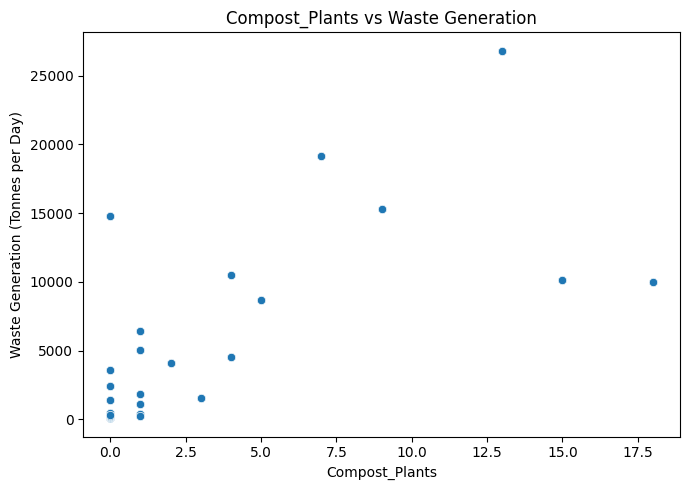

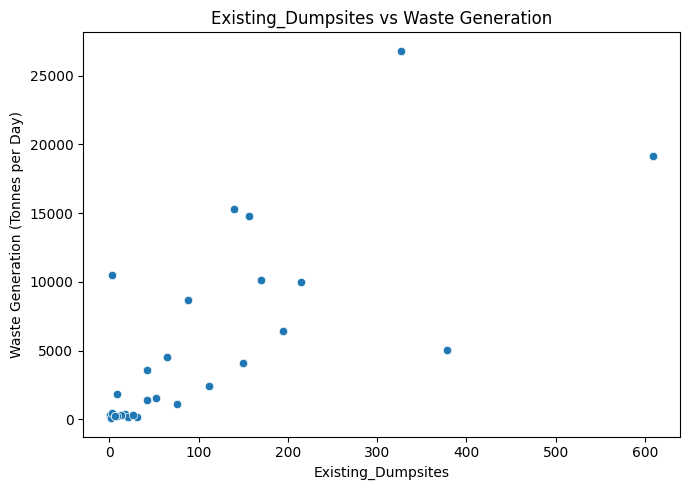

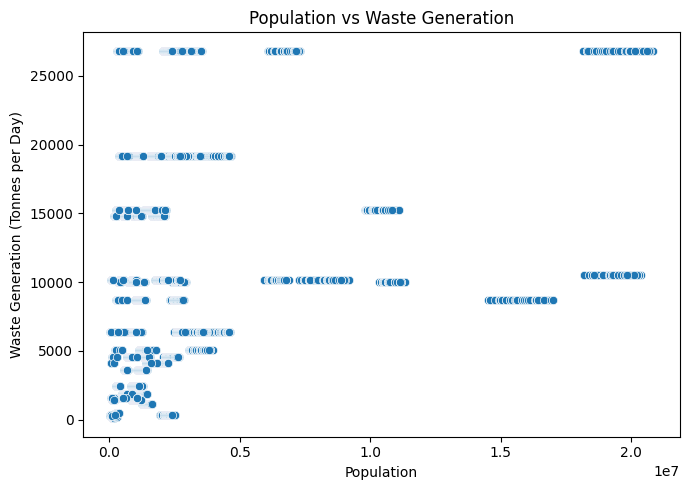

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the features list to fix the NameError
features = [
    "Waste_Collected_Tonnes_Per_Day",
    "Waste_Treated_Tonnes_Per_Day",
    "Compost_Plants",
    "Existing_Dumpsites",
    "Population"
]

for col in features:
    if col in df.columns:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=df, x=col, y=target)
        plt.title(f'{col} vs Waste Generation')
        plt.xlabel(col)
        plt.ylabel('Waste Generation (Tonnes per Day)')
        plt.tight_layout()
        plt.show()

In [48]:
print("CORRELATION WITH WASTE GENERATION")

correlations = df[features + [target]].corr()[target].drop(target)
print(correlations.sort_values(ascending=False))

CORRELATION WITH WASTE GENERATION
Waste_Collected_Tonnes_Per_Day    0.941366
Waste_Treated_Tonnes_Per_Day      0.916411
Existing_Dumpsites                0.664544
Compost_Plants                    0.650677
Population                        0.234413
Name: Waste_Generated_Tonnes_Per_Day, dtype: float64


In [49]:
from sklearn.tree import DecisionTreeRegressor

# Drop rows where the target is NaN before splitting
clean_df = df.dropna(subset=[target]).copy()

if len(clean_df) < 10:
    raise ValueError(
        "Too few observations for this evaluation. "
        "Check the dataset and use an appropriate validation strategy."
    )

# Define X and y from the cleaned dataframe
X = clean_df[features]
y = clean_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

models = {
    'Dummy Regressor': DummyRegressor(strategy='mean'),

    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

trained_models = {}
predictions = {}
results = []

for name, estimator in models.items():

    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', estimator)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results).sort_values('RMSE')

print("MODEL PERFORMANCE COMPARISON")
display(results_df)

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
5,Gradient Boosting,304.638919,1.871937e+05,432.658853,0.997176
4,Random Forest,313.167383,2.305869e+05,480.194689,0.996522
3,Decision Tree,987.295395,2.025578e+06,1423.227922,0.969446
2,Ridge Regression,2090.795369,7.282084e+06,2698.533651,0.890155
1,Linear Regression,2090.795367,7.282084e+06,2698.533653,0.890155
0,Dummy Regressor,6744.901494,6.629451e+07,8142.144071,-0.000003


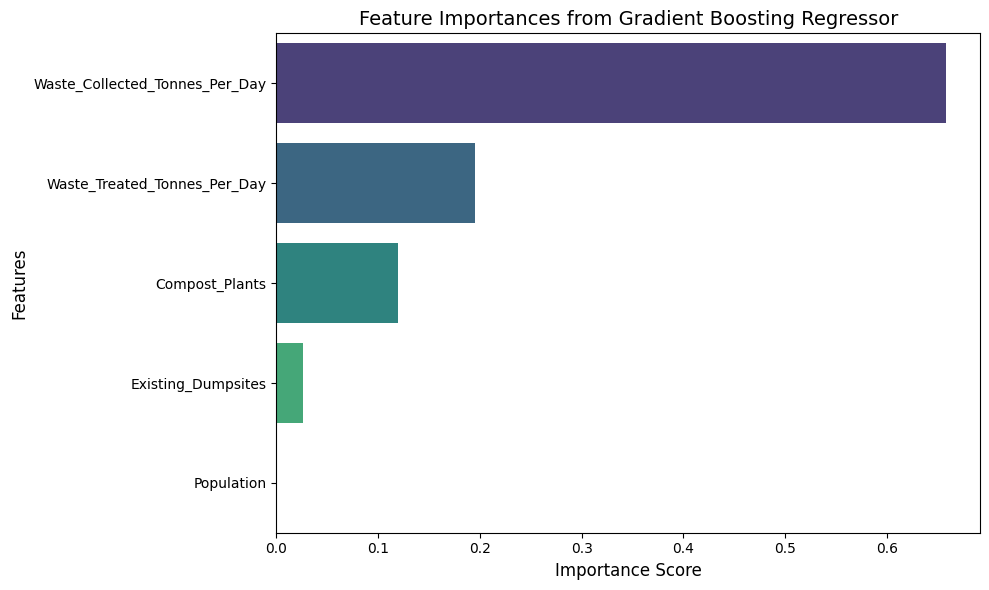

,Feature,Importance
0,Waste_Collected_Tonnes_Per_Day,0.658489
1,Waste_Treated_Tonnes_Per_Day,0.195317
2,Compost_Plants,0.119799
3,Existing_Dumpsites,0.026394
4,Population,0.000000


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract the Gradient Boosting pipeline
gb_pipeline = trained_models['Gradient Boosting']

# Retrieve the feature importances from the estimator step of the pipeline
importances = gb_pipeline.named_steps['model'].feature_importances_

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importances from Gradient Boosting Regressor', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

# Display as a dataframe
display(feature_importance_df)

In [51]:
n_splits = min(5, len(X_train))

if n_splits < 2:
    raise ValueError("Not enough training observations for cross-validation.")

kf = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, estimator in models.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', estimator)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )

    rmse_scores = -scores

    cv_results.append({
        'Model': name,
        'Mean CV RMSE': rmse_scores.mean(),
        'Standard Deviation of CV RMSE': rmse_scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values('Mean CV RMSE')

print("CROSS-VALIDATION RESULTS")
display(cv_df)

CROSS-VALIDATION RESULTS


,Model,Mean CV RMSE,Standard Deviation of CV RMSE
5,Gradient Boosting,448.040603,7.027940
4,Random Forest,474.591368,6.447725
3,Decision Tree,1405.277006,22.958406
2,Ridge Regression,2742.214612,25.319433
1,Linear Regression,2742.214612,25.319433
0,Dummy Regressor,8129.225341,75.938479


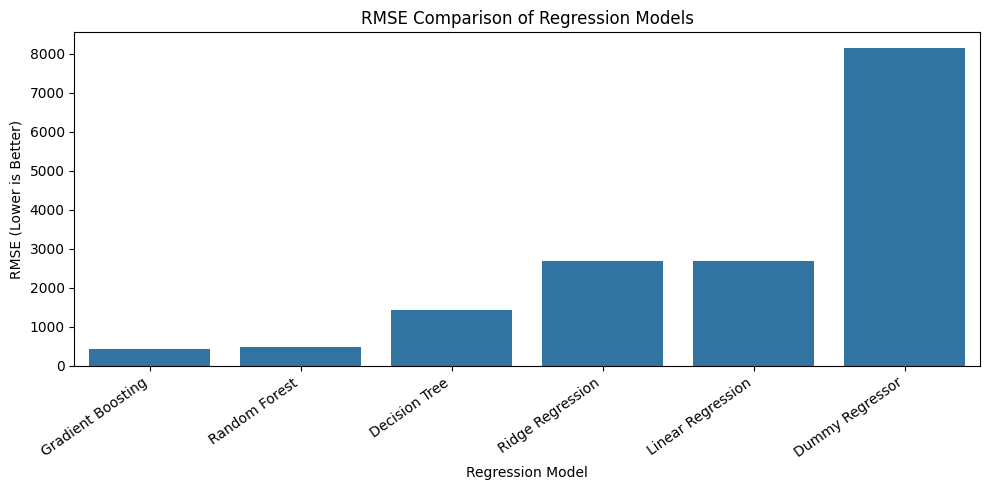

In [52]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('RMSE Comparison of Regression Models')
plt.xlabel('Regression Model')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

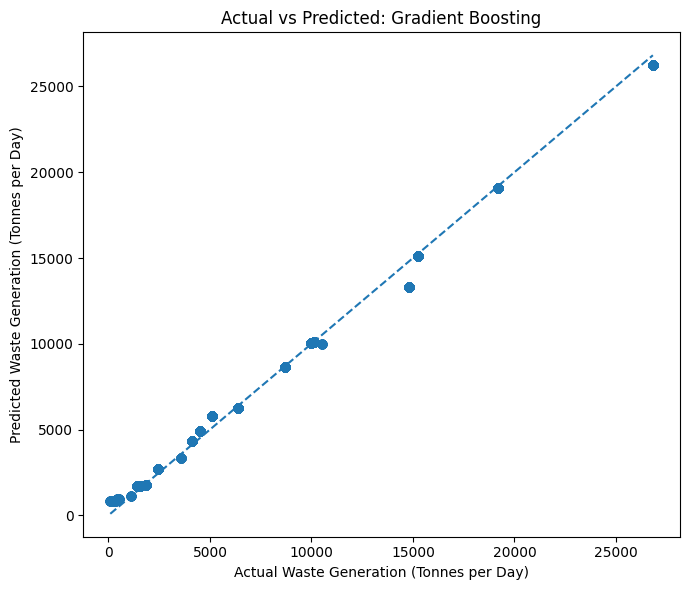

Lowest test RMSE model: Gradient Boosting


In [53]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_pred = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred)

min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Waste Generation (Tonnes per Day)')
plt.ylabel('Predicted Waste Generation (Tonnes per Day)')
plt.title(f'Actual vs Predicted: {best_model_name}')
plt.tight_layout()
plt.show()

print("Lowest test RMSE model:", best_model_name)

In [54]:
results_df.to_csv(
    '/content/MSW_Model_Performance.csv',
    index=False
)

cv_df.to_csv(
    '/content/MSW_Cross_Validation_Results.csv',
    index=False
)

joblib.dump(
    best_model,
    '/content/MSW_Best_Model.pkl'
)

print("Saved files:")
print("1. /content/MSW_Model_Performance.csv")
print("2. /content/MSW_Cross_Validation_Results.csv")
print("3. /content/MSW_Best_Model.pkl")

Saved files:
1. /content/MSW_Model_Performance.csv
2. /content/MSW_Cross_Validation_Results.csv
3. /content/MSW_Best_Model.pkl


In [55]:

# Display actual vs predicted waste generation

import pandas as pd
from IPython.display import display

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_pred = predictions[best_model_name]

prediction_results = pd.DataFrame({
    "Actual Waste Generation (Tonnes/Day)": y_test.values,
    "Predicted Waste Generation (Tonnes/Day)": best_pred
})

prediction_results["Absolute Error"] = (
    prediction_results["Actual Waste Generation (Tonnes/Day)"]
    - prediction_results["Predicted Waste Generation (Tonnes/Day)"]
).abs()

print("Best Model:", best_model_name)
display(prediction_results.head(10).round(2))

# Save prediction results
prediction_results.to_csv(
    "/content/MSW_Prediction_Results.csv",
    index=False
)

print("Prediction results saved successfully!")


Best Model: Gradient Boosting


,Actual Waste Generation (Tonnes/Day),Predicted Waste Generation (Tonnes/Day),Absolute Error
0,10145.0,10088.52,56.48
1,6400.0,6271.46,128.54
2,342.0,824.52,482.52
3,15272.0,15125.83,146.17
4,1576.0,1704.19,128.19
5,5079.0,5799.79,720.79
6,2460.0,2713.41,253.41
7,26820.0,26270.34,549.66
8,1850.0,1795.00,55.00
9,19180.0,19079.85,100.15


Prediction results saved successfully!


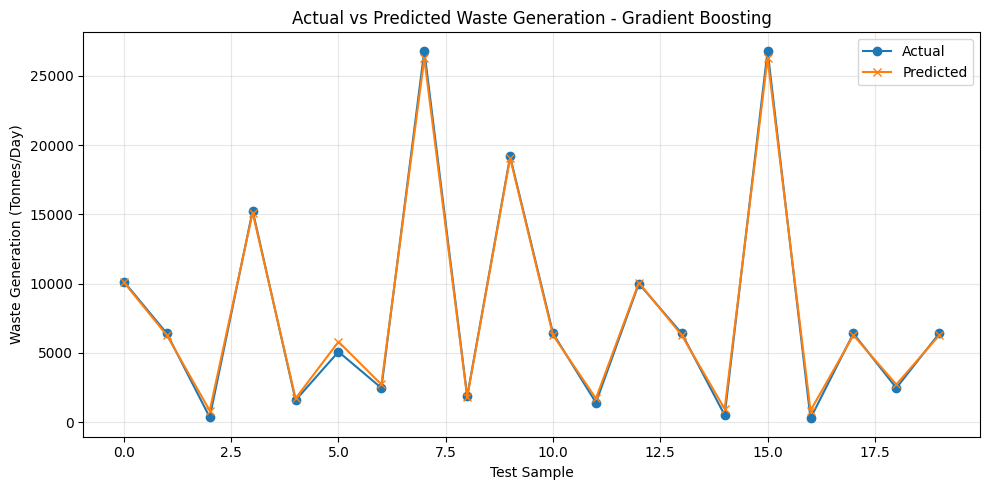

In [56]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    prediction_results["Actual Waste Generation (Tonnes/Day)"].values[:20],
    marker="o",
    label="Actual"
)

plt.plot(
    prediction_results["Predicted Waste Generation (Tonnes/Day)"].values[:20],
    marker="x",
    label="Predicted"
)

plt.title(f"Actual vs Predicted Waste Generation - {best_model_name}")
plt.xlabel("Test Sample")
plt.ylabel("Waste Generation (Tonnes/Day)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [57]:

# Select one test observation
sample = X_test.iloc[[0]]

# Predict its waste generation
predicted_value = best_model.predict(sample)[0]
actual_value = y_test.iloc[0]

print("Model:", best_model_name)
print(f"Actual waste generation: {actual_value:.2f} tonnes/day")
print(f"Predicted waste generation: {predicted_value:.2f} tonnes/day")
print(f"Absolute prediction error: {abs(actual_value - predicted_value):.2f} tonnes/day")


Model: Gradient Boosting
Actual waste generation: 10145.00 tonnes/day
Predicted waste generation: 10088.52 tonnes/day
Absolute prediction error: 56.48 tonnes/day


In [58]:

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training input shape: (18288, 5)
Testing input shape: (4573, 5)
Training target shape: (18288,)
Testing target shape: (4573,)


In [59]:

y_pred = best_model.predict(X_test)

results = pd.DataFrame({
    "Actual Waste (tonnes/day)": np.asarray(y_test),
    "Predicted Waste (tonnes/day)": y_pred
})

results["Absolute Error"] = (
    results["Actual Waste (tonnes/day)"]
    - results["Predicted Waste (tonnes/day)"]
).abs()

display(results.head(10).round(2))

print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R² Score:", round(r2_score(y_test, y_pred), 4))


,Actual Waste (tonnes/day),Predicted Waste (tonnes/day),Absolute Error
0,10145.0,10088.52,56.48
1,6400.0,6271.46,128.54
2,342.0,824.52,482.52
3,15272.0,15125.83,146.17
4,1576.0,1704.19,128.19
5,5079.0,5799.79,720.79
6,2460.0,2713.41,253.41
7,26820.0,26270.34,549.66
8,1850.0,1795.00,55.00
9,19180.0,19079.85,100.15


MAE: 304.64
RMSE: 432.66
R² Score: 0.9972


In [ ]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# Define target and feature columns
feature_cols = ["Population", "Waste_Collected_Tonnes_Per_Day", "Year"]
target_cols = ["Waste_Generated_Tonnes_Per_Day", "Waste_Treated_Tonnes_Per_Day"]

# Drop rows where any of our features or targets contain NaN
clean_df = df.dropna(subset=feature_cols + target_cols).copy()

# Split features and multiple targets
X = clean_df[feature_cols]
y = clean_df[target_cols]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X, y)

print("Model training completed successfully!")

# Get input from the user
population = float(input("Enter population: "))
waste_collected = float(
    input("Enter waste collected (tonnes/day): ")
)
year = int(input("Enter prediction year: "))

# Prepare input
user_input = pd.DataFrame([{
    "Population": population,
    "Waste_Collected_Tonnes_Per_Day": waste_collected,
    "Year": year
}])

# Match the training column structure exactly
user_input = user_input.reindex(columns=feature_cols)

# Predict both outputs
prediction = model.predict(user_input)

print("\n--- Prediction Results ---")
print(f"Year: {year}")
print(f"Predicted Waste Generated: {prediction[0][0]:.2f} tonnes/day")
print(f"Predicted Waste Treated: {prediction[0][1]:.2f} tonnes/day")

Model training completed successfully!
